# Phase 3 — Visualizar meta-máscara `lfw_K4`

Este notebook:
1. Carrega a **última** máscara treinada `lfw_K4` (`LATEST_phase3_lfw_K4.txt`).
2. Visualiza a máscara **sozinha** (magnitude DT-CWT L2/L3 + residual espacial).
3. Aplica a máscara em **3 faces** LFW e mostra antes / depois.
4. Mede a **distância de cosseno** das features FR (original vs protegida).

In [1]:
from __future__ import annotations

import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

REPO_ROOT = Path("..").resolve()
PROTEGO_BASE = REPO_ROOT / "protego_base"
if str(PROTEGO_BASE) not in sys.path:
    sys.path.insert(0, str(PROTEGO_BASE))

from protego.FacialRecognition import FR
from protego.datasets import list_image_paths, resolve_split_dir
from protego.dtcwt_mask import DTCWTMetaMaskModule
from protego.utils import load_imgs

MASK_ROOT = Path("/mnt/study-data/dcarvalho/tests")
LATEST_PTR = MASK_ROOT / "LATEST_phase3_lfw_K4.txt"
N_IMAGES = 3
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)
print("latest pointer:", LATEST_PTR)

/home/dcarvalho/dtcwt_mask_optmization/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda:0
latest pointer: /mnt/study-data/dcarvalho/tests/LATEST_phase3_lfw_K4.txt


/home/dcarvalho/dtcwt_mask_optmization/protego_base/protego/FaceDetection.py:48: FutureWarning: Decorating classes is deprecated and will be disabled in future versions. You should only decorate functions or methods. To preserve the current behavior of class decoration, you can directly decorate the `__init__` method and nothing else.
  @torch.no_grad()


## 1. Carregar checkpoint `lfw_K4`

In [2]:
assert LATEST_PTR.is_file(), f"Pointer not found: {LATEST_PTR}"
mask_path = Path(LATEST_PTR.read_text(encoding="utf-8").strip())
assert mask_path.is_file(), f"Mask missing: {mask_path}"

ckpt = torch.load(mask_path, map_location="cpu", weights_only=False)
cfg = ckpt.get("config", {})
img_size = int(ckpt.get("img_size", cfg.get("img_size", 224)))
fr_name = cfg.get("fr_model", "inception_facenet_vgg")

print("run_id     :", cfg.get("run_id"))
print("mask_path  :", mask_path)
print("fr_model   :", fr_name)
print("final_loss :", ckpt.get("final_loss"))
print("img_size   :", img_size)

for k, v in ckpt["meta_mask"].items():
    print(f"  {k}: shape={tuple(v.shape)}  |mean|={v.abs().mean():.4f}  max|={v.abs().max():.4f}")

mask_mod = DTCWTMetaMaskModule(channels=3, img_size=img_size, J=3, editable_levels=(2, 3))
mask_mod.load_meta_mask_state(ckpt["meta_mask"])
mask_mod = mask_mod.to(DEVICE).eval()
for p in mask_mod.parameters():
    p.requires_grad_(False)

run_id     : 20261012_174514_phase3_lfw_K4
mask_path  : /mnt/study-data/dcarvalho/tests/20261012_174514_phase3_lfw_K4/meta_mask.pt
fr_model   : inception_facenet_vgg
final_loss : 12.63090991973877
img_size   : 224
  delta_mag_2: shape=(1, 3, 6, 56, 56)  |mean|=0.2134  max|=1.3806
  delta_phase_2: shape=(1, 3, 6, 56, 56)  |mean|=0.2300  max|=1.6705
  delta_mag_3: shape=(1, 3, 6, 28, 28)  |mean|=0.2140  max|=1.2742
  delta_phase_3: shape=(1, 3, 6, 28, 28)  |mean|=0.2296  max|=1.4829


## 2. Máscara sozinha (sem face)

- **Magnitude de ΔW** nos níveis 2 e 3 (média RGB, 6 orientações).
- **Residual espacial**: aplicar a máscara a um fundo cinza médio (`0.5`) e mostrar `protegido - 0.5` (efeito da máscara no domínio dos píxeis).

/tmp/ipykernel_3385324/2997319505.py:16: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


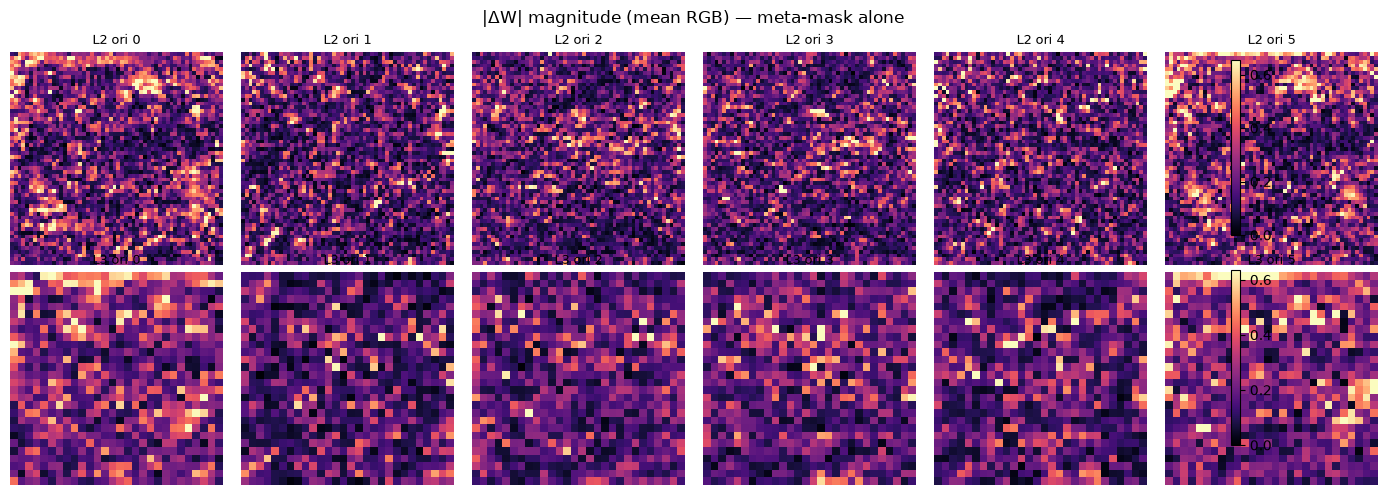

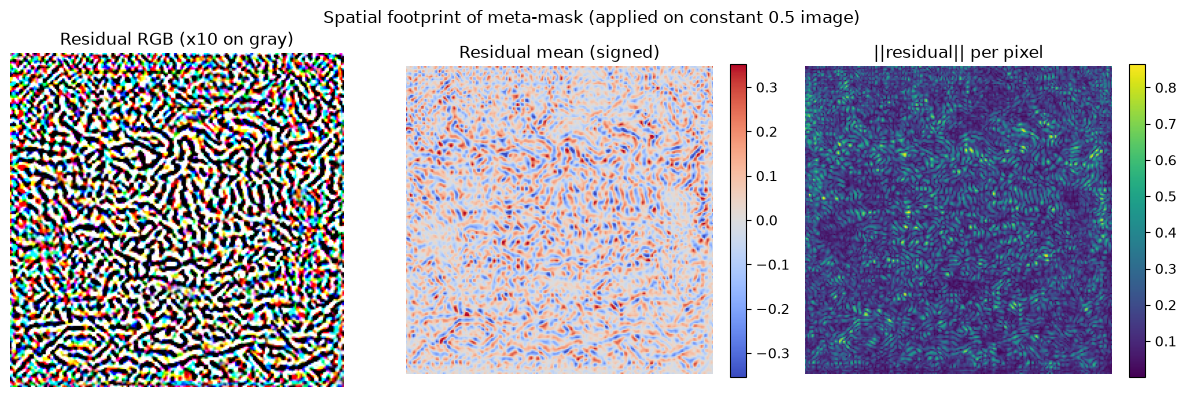

residual stats: mean=0.00002  std=0.13011  linf=0.50000


In [3]:
@torch.no_grad()
def show_mask_alone(module: DTCWTMetaMaskModule, img_size: int = 224):
    # --- polar mag of ΔW per level / orientation ---
    fig, axes = plt.subplots(2, 6, figsize=(14, 5))
    for row, level in enumerate((2, 3)):
        mag = module.delta_mag[str(level)][0].detach().cpu()  # (C,6,H,W)
        mag_rgb = mag.abs().mean(dim=0).numpy()  # (6,H,W)
        vmax = np.percentile(mag_rgb, 99) + 1e-8
        for o in range(6):
            ax = axes[row, o]
            im = ax.imshow(mag_rgb[o], cmap="magma", vmin=0, vmax=vmax)
            ax.set_title(f"L{level} ori {o}", fontsize=9)
            ax.axis("off")
        fig.colorbar(im, ax=axes[row, :].tolist(), fraction=0.02, pad=0.02)
    fig.suptitle("|ΔW| magnitude (mean RGB) — meta-mask alone", fontsize=12)
    plt.tight_layout()
    plt.show()

    # --- spatial residual on mid-gray ---
    gray = torch.full((1, 3, img_size, img_size), 0.5, device=DEVICE)
    prot = module(gray).clamp(0, 1)
    residual = (prot - gray)[0].detach().cpu()
    # amplify for visibility; keep signed view via mean channel
    res_mean = residual.mean(dim=0).numpy()
    res_rgb = residual.permute(1, 2, 0).numpy()
    amp = 10.0  # visualization gain

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(np.clip(res_rgb * amp + 0.5, 0, 1))
    axes[0].set_title(f"Residual RGB (x{amp:g} on gray)")
    axes[0].axis("off")

    im1 = axes[1].imshow(res_mean, cmap="coolwarm", vmin=-res_mean.std() * 3, vmax=res_mean.std() * 3)
    axes[1].set_title("Residual mean (signed)")
    axes[1].axis("off")
    fig.colorbar(im1, ax=axes[1], fraction=0.046)

    mag_map = residual.norm(dim=0).numpy()  # L2 over RGB
    im2 = axes[2].imshow(mag_map, cmap="viridis")
    axes[2].set_title("||residual|| per pixel")
    axes[2].axis("off")
    fig.colorbar(im2, ax=axes[2], fraction=0.046)

    fig.suptitle("Spatial footprint of meta-mask (applied on constant 0.5 image)")
    plt.tight_layout()
    plt.show()

    print(
        f"residual stats: mean={residual.mean():.5f}  std={residual.std():.5f}  "
        f"linf={residual.abs().max():.5f}"
    )

show_mask_alone(mask_mod, img_size=img_size)

## 3. Antes / depois em 3 imagens + distância de cosseno

Distância de cosseno entre embeddings FR:

$$d_{\cos}(a,b) = 1 - \frac{a^\top b}{\|a\|\|b\|}$$

(0 = idêntico; valores maiores = mais afastado no espaço da rede.)

In [4]:
fr = FR(model_name=fr_name, device=DEVICE)
fr.fr_model.model.eval()
for p in fr.fr_model.model.parameters():
    p.requires_grad_(False)

split_dir = resolve_split_dir("lfw_frontal", "test")
all_paths = list_image_paths(split_dir)
# deterministic pick of 3 faces spaced across the split
idxs = np.linspace(0, len(all_paths) - 1, num=N_IMAGES, dtype=int)
paths = [all_paths[i] for i in idxs]
print("images:")
for p in paths:
    print(" -", p)

imgs = load_imgs(img_paths=paths, img_sz=img_size, drange=1, device=DEVICE)  # (3,3,H,W)

with torch.no_grad():
    protected = mask_mod(imgs).clamp(0, 1)
    feat_orig = F.normalize(fr(imgs), p=2, dim=1)
    feat_prot = F.normalize(fr(protected), p=2, dim=1)
    cos_sim = (feat_orig * feat_prot).sum(dim=1)
    cos_dist = 1.0 - cos_sim

print("\nCosine distance (original vs protected):")
for i, p in enumerate(paths):
    print(f"  [{i}] {Path(p).name}:  d_cos={cos_dist[i].item():.4f}  (sim={cos_sim[i].item():.4f})")
print(f"  mean d_cos = {cos_dist.mean().item():.4f}")

images:
 - /mnt/databases/faces/lfw_frontal/faces_test/img_000000.jpg
 - /mnt/databases/faces/lfw_frontal/faces_test/img_006572.jpg
 - /mnt/databases/faces/lfw_frontal/faces_test/img_013231.jpg

Cosine distance (original vs protected):
  [0] img_000000.jpg:  d_cos=0.9842  (sim=0.0158)
  [1] img_006572.jpg:  d_cos=0.8421  (sim=0.1579)
  [2] img_013231.jpg:  d_cos=0.7469  (sim=0.2531)
  mean d_cos = 0.8578


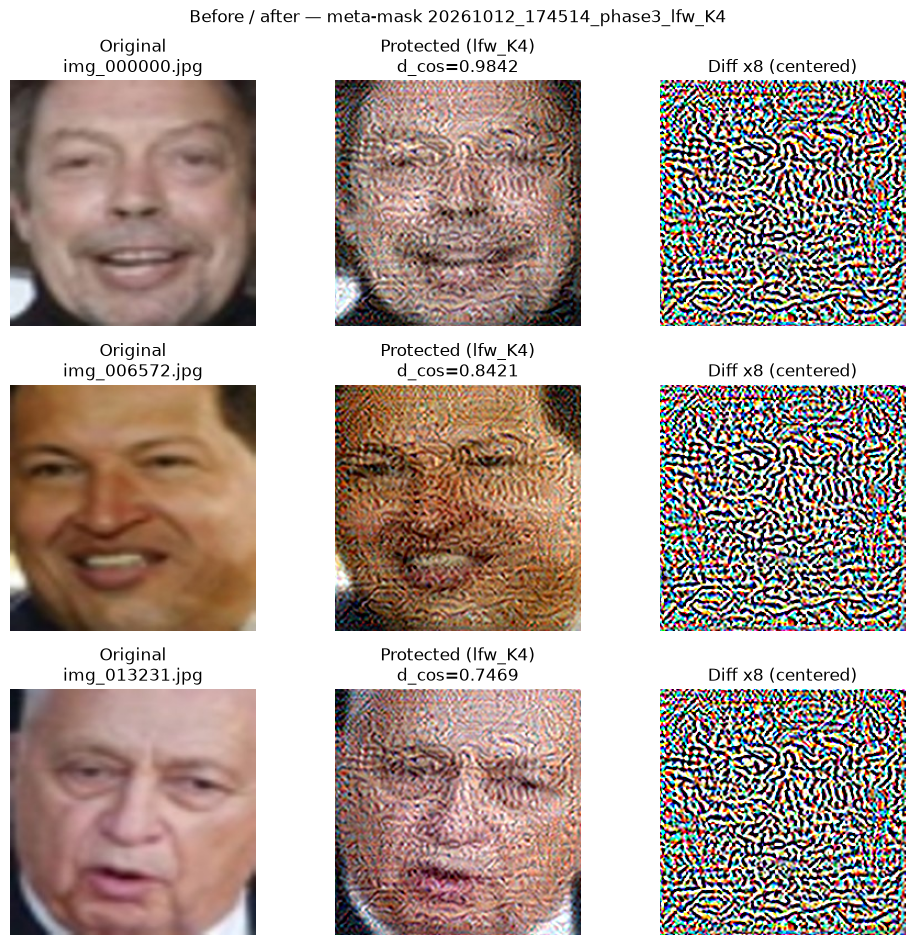

In [5]:
def to_np_img(t: torch.Tensor) -> np.ndarray:
    return t.detach().cpu().permute(1, 2, 0).clamp(0, 1).numpy()

fig, axes = plt.subplots(N_IMAGES, 3, figsize=(10, 3.2 * N_IMAGES))
if N_IMAGES == 1:
    axes = np.expand_dims(axes, 0)

for i in range(N_IMAGES):
    orig = to_np_img(imgs[i])
    prot = to_np_img(protected[i])
    diff = np.clip((prot - orig) * 8 + 0.5, 0, 1)  # amplify residual for display

    axes[i, 0].imshow(orig)
    axes[i, 0].set_title(f"Original\n{Path(paths[i]).name}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(prot)
    axes[i, 1].set_title(f"Protected (lfw_K4)\nd_cos={cos_dist[i].item():.4f}")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(diff)
    axes[i, 2].set_title("Diff x8 (centered)")
    axes[i, 2].axis("off")

fig.suptitle(f"Before / after — meta-mask {cfg.get('run_id')}", fontsize=12)
plt.tight_layout()
plt.show()

## 4. Tabela resumo

In [ ]:
import pandas as pd

rows = []
for i, p in enumerate(paths):
    rows.append({
        "image": Path(p).name,
        "cos_similarity": float(cos_sim[i]),
        "cos_distance": float(cos_dist[i]),
        "l2_pixel": float((protected[i] - imgs[i]).pow(2).mean().sqrt()),
        "linf_pixel": float((protected[i] - imgs[i]).abs().max()),
    })
df = pd.DataFrame(rows)
display(df)
print("mean cos_distance:", df["cos_distance"].mean())